In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'CSNA3.SA'
nome_modelo = f'{papel}_val_2pct'
valorizacao = 0.02

In [ ]:
base = datetime.today().date() - timedelta(days=1)
df = pp.montar_dataset(papel, dias_total_historico=600, data_base=base, x_pct=valorizacao)
df.tail(10)

Baixando dados do yfinance para CSNA3.SA de 2022-11-26 a 2025-05-14...
YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


Dados salvos em cache: ../dados\CSNA3.SA_2022-11-26_2025-05-14.csv
⬇️ Baixando dados macro de 26/11/2021 a 15/05/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: ../dados\macro_20211126_20250515.csv
Baixando dados do yfinance para ^BVSP de 2022-11-26 a 2025-05-14...


[*********************100%***********************]  1 of 1 completed

Dados salvos em cache: ../dados\^BVSP_2022-11-26_2025-05-14.csv


,index,close,pct_change,vol,rsi,macd,macd_signal,macd_hist,selic,ipca,dolar,index_ibov,close_ibov,Target
data,,,,,,,,,,,,,,
2025-04-30,1970-01-01 00:00:00.000000603,9.30,-0.010638,0.018940,55.324289,0.061748,-0.027683,0.089431,14.25,0.43,5.6608,603,135067.0,1.0
2025-05-02,1970-01-01 00:00:00.000000604,9.35,0.005376,0.013289,56.274816,0.075692,-0.007008,0.082700,14.25,0.43,5.6394,604,135134.0,1.0
2025-05-05,1970-01-01 00:00:00.000000605,9.20,-0.016043,0.015181,52.655375,0.073788,0.009151,0.064637,14.25,0.43,5.6520,605,133491.0,1.0
2025-05-06,1970-01-01 00:00:00.000000606,9.34,0.015217,0.015392,55.530213,0.082624,0.023846,0.058778,14.25,0.43,5.7210,606,133516.0,1.0
2025-05-07,1970-01-01 00:00:00.000000607,9.40,0.006424,0.014791,56.742504,0.093391,0.037755,0.055636,14.25,0.43,5.7375,607,133398.0,1.0
2025-05-08,1970-01-01 00:00:00.000000608,9.63,0.024468,0.013539,61.118265,0.119111,0.054026,0.065084,14.75,0.43,5.6860,608,136232.0,NaN
2025-05-09,1970-01-01 00:00:00.000000609,8.68,-0.098650,0.034250,42.151758,0.062120,0.055645,0.006475,14.75,0.43,5.6511,609,136512.0,NaN
2025-05-12,1970-01-01 00:00:00.000000610,8.89,0.024194,0.035560,46.131303,0.033514,0.051219,-0.017705,14.75,0.43,5.6822,610,136563.0,NaN
2025-05-13,1970-01-01 00:00:00.000000611,9.03,0.015748,0.036158,48.666632,0.021887,0.045352,-0.023465,14.75,0.43,5.6262,611,138963.0,NaN


In [6]:
df['Target'].value_counts()

Target
0.0    313
1.0    294
Name: count, dtype: int64

In [7]:
# Parâmetros
DIAS_JANELA_X = 60  # janela de dados recentes que formam cada X
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [8]:
# Preparar X e y para treino
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO)

In [9]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=6,
                                        min_samples_leaf=10,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo.fit(X_train.values, y_train.values)


RandomForestClassifier(max_depth=6, min_samples_leaf=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

Avaliar e logar modelo
MLflow Run ID: 10541b88927f4538afc01bca5e2ab000 para CSNA3.SA_val_2pct

--- Conjunto de Treino --- Geral

Relatório de Validação (threshold = 0.5):
              precision    recall  f1-score   support

         0.0       0.90      0.91      0.91       247
         1.0       0.90      0.88      0.89       211

    accuracy                           0.90       458
   macro avg       0.90      0.90      0.90       458
weighted avg       0.90      0.90      0.90       458

Precisão (classe 1): 0.8985507246376812
Recall (classe 1): 0.8815165876777251
AUC no treino: 0.958

--- Conjunto de Treino --- Janelas
→ Threshold calibrado para recall ≥ 0.2: 0.68

Avaliação com Janela Deslizante (30 dias):
Precisão média (em 326 janelas com previsão positiva): 1.000
Recall médio: 0.345
Acurácia média: 0.722

Threshold ideal baseado em recall mínimo: 0.77

--- Conjunto de Validação --- Geral

Relatório de Validação (threshold = 0.7712393428459225):
              precision    reca

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\treinamento.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumo = df_probas.groupby('faixa').agg(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Modelo CSNA3.SA_val_2pct salvo na run 10541b88927f4538afc01bca5e2ab000


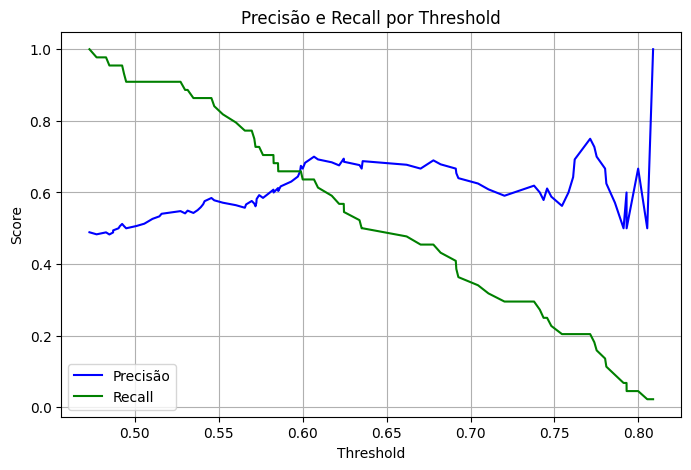

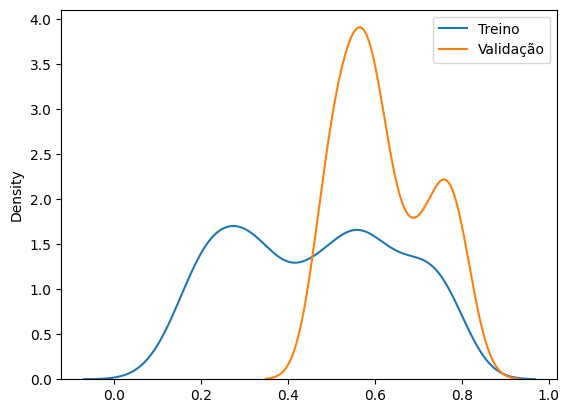

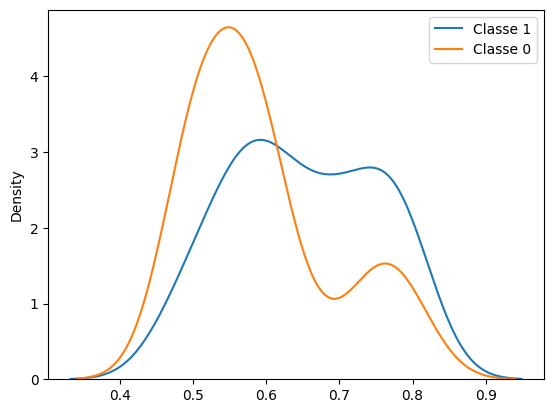

In [16]:
resultado = tr.avaliar_e_logar_modelo(modelo, papel, nome_modelo, X_train, y_train, X_validacao, y_validacao, dias_janela=DIAS_JANELA_X, valorizacao=valorizacao, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.2, window_size=30)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

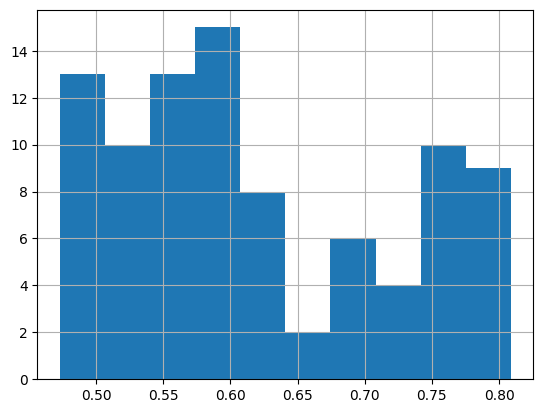

In [17]:
pd.Series(probas).hist()

# Redução de features

In [18]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


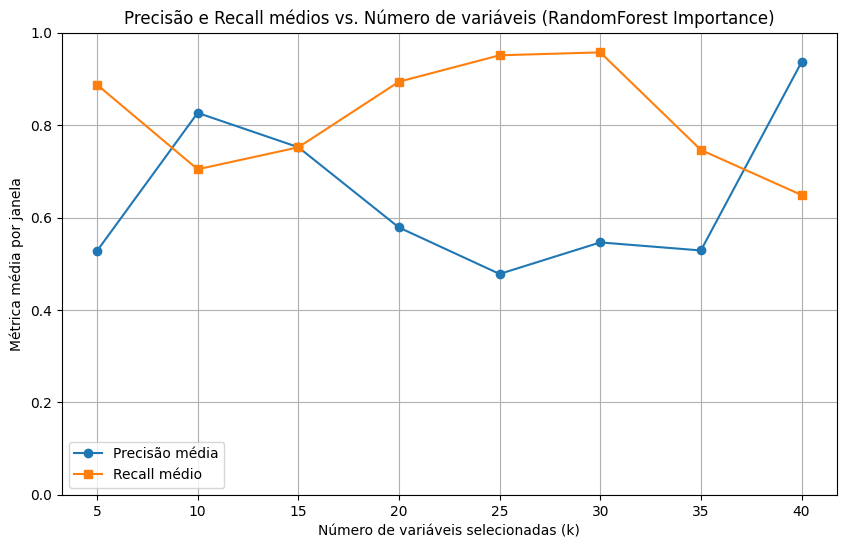

In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas: 20

In [20]:
n_features = 20
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['retorno_acumulado',
 'close_dist_min',
 'close_min',
 'rsi_ultimo',
 'close_mean',
 'macd_signal_std',
 'retorno_mean',
 'ibov_std',
 'close_ult_vs_mm',
 'retorno_std',
 'macd_conf_mean',
 'macd_signal_ultimo',
 'macd_ultimo',
 'macd_hist_std',
 'macd_hist_abs_mean',
 'ibov_amplitude',
 'close_amplitude',
 'close_max',
 'ibov_trend',
 'close_std']

In [21]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [22]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=6,
                                        min_samples_leaf=10,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)


RandomForestClassifier(max_depth=6, min_samples_leaf=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

Avaliar e logar modelo
MLflow Run ID: cf19243d00d04e52900f732e5a4d06b3 para CSNA3.SA_val_2pct

--- Conjunto de Treino --- Geral

Relatório de Validação (threshold = 0.5):
              precision    recall  f1-score   support

         0.0       0.88      0.91      0.89       247
         1.0       0.89      0.85      0.87       211

    accuracy                           0.88       458
   macro avg       0.88      0.88      0.88       458
weighted avg       0.88      0.88      0.88       458

Precisão (classe 1): 0.8861386138613861
Recall (classe 1): 0.8483412322274881
AUC no treino: 0.948

--- Conjunto de Treino --- Janelas
→ Threshold calibrado para recall ≥ 0.2: 0.70

Avaliação com Janela Deslizante (30 dias):
Precisão média (em 320 janelas com previsão positiva): 1.000
Recall médio: 0.325
Acurácia média: 0.712

Threshold ideal baseado em recall mínimo: 0.61

--- Conjunto de Validação --- Geral

Relatório de Validação (threshold = 0.6053736151018069):
              precision    reca

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\treinamento.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumo = df_probas.groupby('faixa').agg(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Modelo CSNA3.SA_val_2pct salvo na run cf19243d00d04e52900f732e5a4d06b3


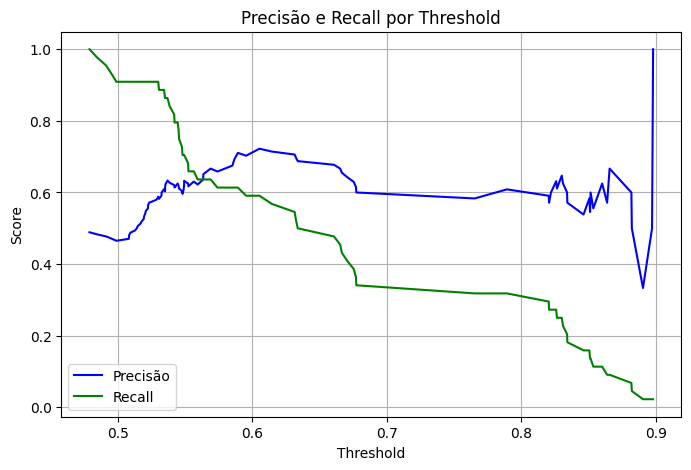

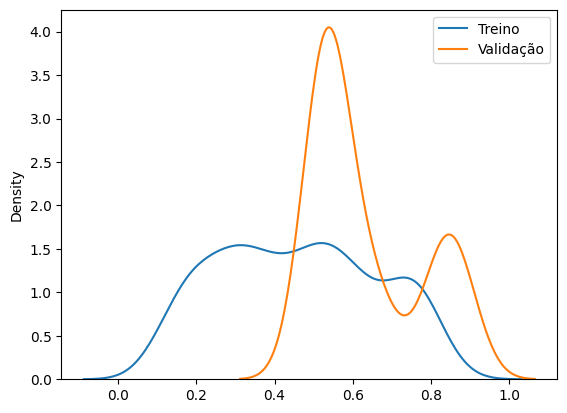

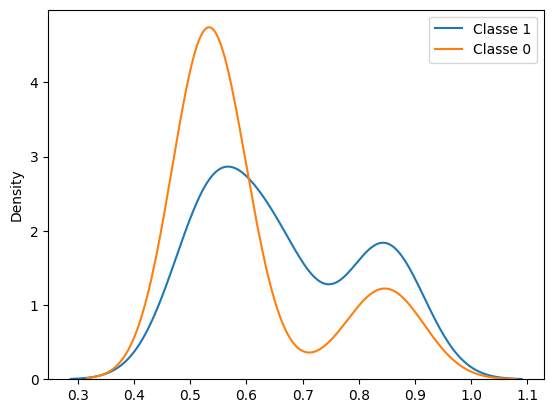

In [24]:
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, nome_modelo, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela=DIAS_JANELA_X, valorizacao=valorizacao, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.2, window_size=30)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

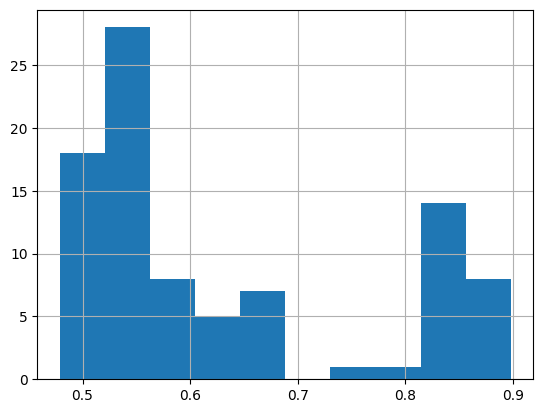

In [25]:
pd.Series(probas).hist()